# Predicción de impago de tarjetas de crédito: modelado

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, precision_recall_curve,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
FEATURES_PATH = "credit_features.csv"
TRAIN_PATH = "credit_train.csv"
TEST_PATH = "credit_test.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
TARGET = "default"
CV_SCORING = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "brier": "neg_brier_score",
}
CPU_CORES = 8
os.environ["LOKY_MAX_CPU_COUNT"] = str(CPU_CORES)

## 1. Introducción

Este notebook parte de `credit_features.csv`, generado al final de `01_EDA_CC`, que hay que ejecutar antes. Contiene las 17 variables seleccionadas en la ingeniería de variables y la variable objetivo `default` (1 = impago en octubre de 2005).

El objetivo es entrenar y comparar modelos de impago con el conjunto de entrenamiento y elegir el modelo final. La evaluación del modelo elegido (umbral, calibración, test e interpretabilidad) y las conclusiones están en `03_Evaluacion_CC`, que parte de los ficheros `credit_train.csv` y `credit_test.csv` generados aquí.

Proyecto educativo: los datos son de 2005 y de un único mercado, y el modelo no está pensado para decisiones reales de crédito.

## 2. Carga de datos

In [3]:
credit_features = pd.read_csv(FEATURES_PATH)

categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "STATUS_1"]
numeric_features = [
    "AGE", "AGE_SQUARED_DEVIATION", "LOG_LIMIT",
    "DELAY_1", "MONTHS_DELAYED", "WORST_DELAY", "MONTHS_PAID_FULL",
    "UTILIZATION_MEAN", "PAYMENT_RATIO_MEAN", "DEBT_TREND",
    "LOG_PAYMENT_LAST", "LOG_PAYMENT_MEAN", "INACTIVE",
]
model_features = categorical_features + numeric_features

pd.Series({
    "filas": len(credit_features),
    "variables": len(model_features),
    "columnas coinciden": set(model_features + [TARGET]) == set(credit_features.columns),
    "nulos": credit_features.isna().sum().sum(),
})

filas                 30000
variables                17
columnas coinciden     True
nulos                     0
dtype: object

## 3. Partición en entrenamiento y test

Reservamos un 20 % de los clientes como conjunto de test. La partición es estratificada para mantener la misma proporción de impagos en ambos conjuntos.

A partir de aquí, todas las decisiones (modelo, hiperparámetros, umbral y calibración) se toman solo con el conjunto de entrenamiento. El test se usa una única vez, al final, para medir el rendimiento con clientes que el modelo no ha visto.

In [4]:
X = credit_features[model_features]
y = credit_features[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

In [5]:
pd.DataFrame({
    "clientes": [len(y_train), len(y_test)],
    "impagos": [y_train.sum(), y_test.sum()],
    "tasa_impago": [y_train.mean(), y_test.mean()],
}, index=["entrenamiento", "test"]).round(3)

,clientes,impagos,tasa_impago
entrenamiento,24000,5309,0.221
test,6000,1327,0.221


El entrenamiento tiene 24.000 clientes (5.309 impagos) y el test 6.000 (1.327 impagos). Ambos mantienen la tasa de impago del 22,1 %. Con 1.327 impagos en el test, las métricas finales serán estables: un recall del 60 %, por ejemplo, tendría un intervalo de confianza de unos ±2,6 puntos.

Guardamos ambos conjuntos, con la variable objetivo, en `credit_train.csv` y `credit_test.csv`. 

In [6]:
pd.concat([X_train, y_train], axis=1).to_csv(TRAIN_PATH, index=False)
pd.concat([X_test, y_test], axis=1).to_csv(TEST_PATH, index=False)

pd.Series({
    "credit_train.csv": len(pd.read_csv(TRAIN_PATH)),
    "credit_test.csv": len(pd.read_csv(TEST_PATH)),
}, name="filas")

credit_train.csv    24000
credit_test.csv      6000
Name: filas, dtype: int64

## 4. Validación cruzada

Dividimos el entrenamiento en 5 particiones de unos 4.800 clientes, todas con la misma proporción de impagos (22,1 %): eso es lo que significa «estratificada». Entrenamos 5 veces, dejando fuera cada vez una partición distinta para evaluar, y promediamos los resultados. Así comparamos modelos e hiperparámetros sin tocar el test.

In [7]:
cross_validation = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

## 5. Modelo de referencia: regresión logística

La regresión logística es el modelo base usado por bancos para este tipo de actividades. Es estable y sus coeficientes se leen como efectos sobre el riesgo. Fija el listón que los modelos más complejos tendrán que superar.

No reequilibramos las clases (`class_weight="balanced"`), porque inflaría las probabilidades y empeoraría la calibración. El desequilibrio se gestiona con el umbral de decisión.

### 5.1 Pipeline

- **Variables categóricas**: aplicamos one-hot con `drop="first"`. Cada coeficiente se interpreta respecto a una categoría de referencia (la primera en orden alfabético): `hombre`, `bachillerato`, `casado` y `pago_total`.
- **Variables Numéricas**: estandarizadas, para que los coeficientes sean comparables entre sí (efecto de una desviación estándar).

In [8]:
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(drop="first"), categorical_features),
    ("numeric", StandardScaler(), numeric_features),
])

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])

### 5.2 Regularización

Probamos cuatro valores de `C` y elegimos el que maximiza la PR-AUC media en nuestra validación.

In [9]:
logistic_search = GridSearchCV(
    logistic_pipeline,
    param_grid={"classifier__C": [0.01, 0.1, 1, 10]},
    scoring="average_precision",
    cv=cross_validation,
)
logistic_search.fit(X_train, y_train)

search_results = pd.DataFrame(logistic_search.cv_results_)
search_results[["param_classifier__C", "mean_test_score", "std_test_score"]].round(4)

,param_classifier__C,mean_test_score,std_test_score
0,0.01,0.5318,0.0117
1,0.1,0.5337,0.0114
2,1,0.5345,0.0116
3,10,0.5346,0.0116


La regularización apenas influye: la PR-AUC va de 0,532 a 0,535, una diferencia menor que la variación entre particiones (±0,012). La búsqueda elige `C = 10`.

### 5.3 Métricas en validación cruzada

Evaluamos el modelo elegido con ROC-AUC, PR-AUC y Brier score, que no dependen del umbral de decisión.


NOTAS:
- ROC-AUC mide la capacidad del modelo de distinguir entre clases positivas y negativas en cada uno de los umbrales de decisión posibles.
- PR-AUC evalúa modelos de clasificación, útil en un conjunto desbalanceado como este. Se diferencia de ROC-AUC por ignorar los verdaderos negativos centrandose en la clase positiva.
- Brier score evalúa la precisión de las predicciones probabilisticas. Cuanto más cercano a 0 más se acerca a una predicción perfecta. 
- Por ejemplo. Un modelo sin capacidad predictiva tendría una ROC-AUC de 0,5 y una PR-AUC igual a la tasa de impago (0,221). Predecir siempre la tasa de impago daría un Brier score de 0,221 × 0,779 = 0,172. Cuanto más bajo, mejor.



In [10]:
best_logistic = logistic_search.best_estimator_
logistic_cv = cross_validate(
    best_logistic, X_train, y_train, cv=cross_validation, scoring=CV_SCORING
)

logistic_metrics = pd.DataFrame({
    "media": [
        logistic_cv["test_roc_auc"].mean(),
        logistic_cv["test_pr_auc"].mean(),
        -logistic_cv["test_brier"].mean(),
    ],
    "desviacion": [
        logistic_cv["test_roc_auc"].std(),
        logistic_cv["test_pr_auc"].std(),
        logistic_cv["test_brier"].std(),
    ],
}, index=["ROC-AUC", "PR-AUC", "Brier score"])
logistic_metrics.round(4)

,media,desviacion
ROC-AUC,0.7775,0.0067
PR-AUC,0.5346,0.0116
Brier score,0.1365,0.0017


El modelo tiene una capacidad predictiva moderada y estable entre particiones:

| Métrica | Logística | Sin capacidad predictiva |
|---|---|---|
| ROC-AUC | 0,778 (±0,007) | 0,500 |
| PR-AUC | 0,535 (±0,012) | 0,221 |
| Brier score | 0,137 (±0,002) | 0,172 |

- La **ROC-AUC de 0,78** significa que, si elegimos al azar un cliente que impaga y otro que no, el modelo asigna más riesgo al primero en el 78 % de los casos.
- La **PR-AUC de 0,535** multiplica por 2,4 la de un modelo sin capacidad predictiva.
- El **Brier score** reduce un 21 % el error de predecir siempre la tasa media.

Es el listón que los modelos de árboles de la sección 6 tendrán que superar.

### 5.4 Coeficientes

Con las variables numéricas estandarizadas, cada coeficiente mide el efecto sobre el riesgo de impago en escala log-odds (logaritmo de la probabilidad u "odd"). Positivo significa más riesgo.

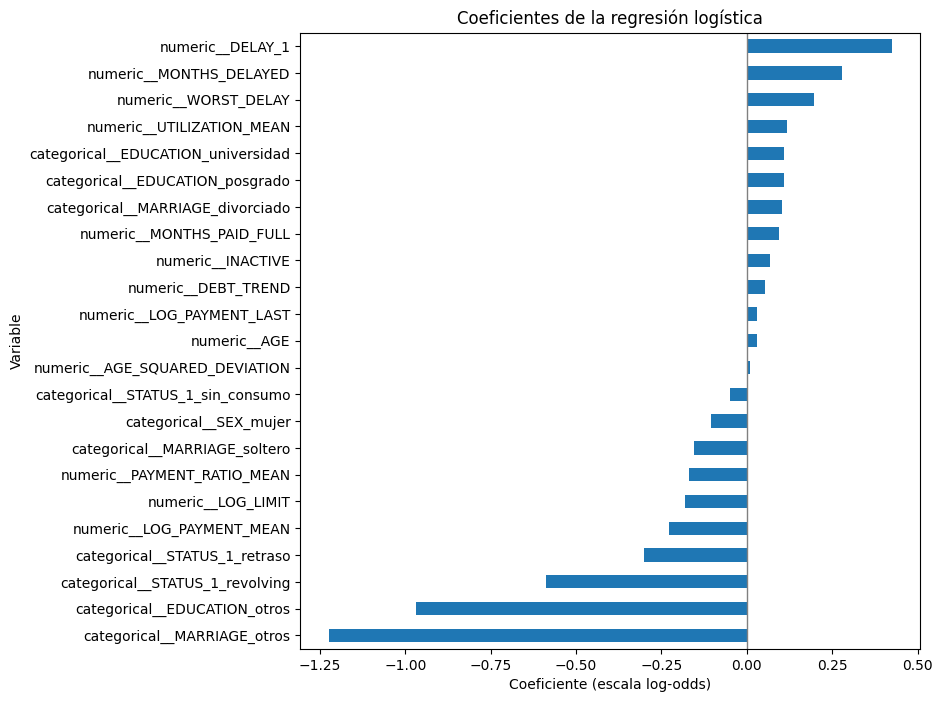

In [11]:
coefficient_names = best_logistic.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.Series(
    best_logistic.named_steps["classifier"].coef_[0], index=coefficient_names
).sort_values()

ax = coefficients.plot(kind="barh", figsize=(8, 8))
ax.axvline(0, color="grey", linewidth=1)
ax.set_title("Coeficientes de la regresión logística")
ax.set_xlabel("Coeficiente (escala log-odds)")
ax.set_ylabel("Variable")
plt.show()

Unos apuntes:
- **El retraso es lo que más pesa:** `DELAY_1`, `MONTHS_DELAYED` y `WORST_DELAY` aumentan el riesgo. El coeficiente negativo de `STATUS_1_retraso` no lo contradice: el efecto del retraso se reparte entre esa categoría y `DELAY_1`, y en conjunto es claramente positivo.
- **También observamos algunos comportamientos esperados.** Pagar más y tener más límite reduce el riesgo, y usar más el límite lo aumenta.
- **Las variables demográficas pesan poco** una vez se tiene en cuenta el comportamiento de pago.



## 6. Modelos de árboles

Probamos dos modelos más flexibles que la regresión logística, capaces de captar relaciones no lineales e interacciones entre variables:

- **Random Forest**: muchos árboles independientes cuyas predicciones se promedian.
- **Gradient boosting** (`HistGradientBoostingClassifier`): árboles pequeños entrenados en secuencia, cada uno corrigiendo los errores del anterior.

Fijamos uun criterio: un modelo solo compensa si mejora la PR AUC mejora la métrica de la regresión logistica. 

La motivación de esto es el desbalanceo del dataset y queu la variable que nos interesa son los positivos. Con esto "no inflamos" el valor con los negativos.

In [12]:
tree_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(), categorical_features),
    ("numeric", "passthrough", numeric_features),
])

Ajustamos cada modelo con `GridSearchCV`, una rejilla pequeña y las mismas particiones que la logística, y nos quedamos con la combinación de mejor PR-AUC. La función `best_cv_metrics` resume las métricas de validación de esa combinación.

In [13]:
def best_cv_metrics(search):
    best_row = pd.DataFrame(search.cv_results_).iloc[search.best_index_]
    return pd.Series({
        "ROC-AUC": best_row["mean_test_roc_auc"],
        "PR-AUC": best_row["mean_test_pr_auc"],
        "PR-AUC desviación": best_row["std_test_pr_auc"],
        "Brier score": -best_row["mean_test_brier"],
    })

### 6.1 Random Forest

Probamos la profundidad máxima de los árboles y el número mínimo de clientes por hoja, los dos parámetros que más controlan el sobreajuste, con 300 árboles.

In [14]:
forest_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE
    )),
])

forest_search = GridSearchCV(
    forest_pipeline,
    param_grid={
        "classifier__max_depth": [8, 12, None],
        "classifier__min_samples_leaf": [20, 50],
    },
    scoring=CV_SCORING,
    refit="pr_auc",
    cv=cross_validation,
    return_train_score=True,
)
forest_search.fit(X_train, y_train)
forest_search.best_params_

{'classifier__max_depth': 12, 'classifier__min_samples_leaf': 20}

### 6.2 Gradient boosting

Probamos la tasa de aprendizaje y el número máximo de hojas por árbol. La parada temprana deja de añadir árboles cuando el modelo deja de mejorar, lo que limita el sobreajuste.

In [15]:
boosting_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=500, early_stopping=True, random_state=RANDOM_STATE
    )),
])

boosting_search = GridSearchCV(
    boosting_pipeline,
    param_grid={
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_leaf_nodes": [15, 31],
    },
    scoring=CV_SCORING,
    refit="pr_auc",
    cv=cross_validation,
    return_train_score=True,
)
boosting_search.fit(X_train, y_train)
boosting_search.best_params_

{'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 31}

### 6.3 Comparación con la regresión logística

Métricas de validación cruzada de los tres modelos, con las mismas cinco particiones.

In [16]:
model_comparison = pd.DataFrame({
    "Regresión logística": {
        "ROC-AUC": logistic_metrics.loc["ROC-AUC", "media"],
        "PR-AUC": logistic_metrics.loc["PR-AUC", "media"],
        "PR-AUC desviación": logistic_metrics.loc["PR-AUC", "desviacion"],
        "Brier score": logistic_metrics.loc["Brier score", "media"],
    },
    "Random Forest": best_cv_metrics(forest_search),
    "Gradient boosting": best_cv_metrics(boosting_search),
}).T
model_comparison[["ROC-AUC", "PR-AUC", "PR-AUC desviación", "Brier score"]].round(4)

,ROC-AUC,PR-AUC,PR-AUC desviación,Brier score
Regresión logística,0.7775,0.5346,0.0116,0.1365
Random Forest,0.7874,0.5625,0.0069,0.1331
Gradient boosting,0.7849,0.5589,0.0066,0.1335


| Modelo | ROC-AUC | PR-AUC | Brier score |
|---|---|---|---|
| Regresión logística | 0,778 | 0,535 | 0,137 |
| Random Forest | 0,787 | 0,563 | 0,133 |
| Gradient boosting | 0,785 | 0,559–0,561 | 0,133 |

Los dos modelos de árboles mejoran la PR-AUC de la logística. Sin embargo parece haber un empate entre ellos hay un empate.

### 6.4 Aciertos y errores de cada modelo

Para contar aciertos y errores, cada cliente necesita una probabilidad y un umbral que la convierta en una decisión (1 = se marca como riesgo de impago).

Usamos predicciones **fuera de partición** (`cross_val_predict`): cada cliente de entrenamiento recibe la probabilidad del modelo entrenado con las otras cuatro particiones. Así evaluamos los 24.000 clientes sin tocar el test.

In [17]:
candidate_models = {
    "Regresión logística": best_logistic,
    "Random Forest": forest_search.best_estimator_,
    "Gradient boosting": boosting_search.best_estimator_,
}

out_of_fold_probabilities = {}
for model_name, model in candidate_models.items():
    probabilities = cross_val_predict(
        model, X_train, y_train, cv=cross_validation, method="predict_proba"
    )
    out_of_fold_probabilities[model_name] = probabilities[:, 1]

La función `threshold_metrics` cuenta, para un umbral dado, los impagos detectados (verdaderos positivos), los que se escapan (falsos negativos) y los buenos clientes marcados (falsos positivos), y calcula la precisión, el recall y el F1.

In [18]:
def threshold_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    true_negatives, false_positives, false_negatives, true_positives = confusion_matrix(
        y_true, predictions
    ).ravel()
    precision = true_positives / (true_positives + false_positives)
    recall = true_positives / (true_positives + false_negatives)
    return {
        "umbral": threshold,
        "% marcados": predictions.mean() * 100,
        "impagos detectados (VP)": true_positives,
        "impagos no detectados (FN)": false_negatives,
        "buenos marcados (FP)": false_positives,
        "precisión": precision,
        "recall": recall,
        "F1": 2 * precision * recall / (precision + recall),
    }

Para que la comparación sea justa, todos los modelos marcan **el mismo porcentaje de clientes**: el 5 %, 10 %, 20 % o 30 % con más riesgo según cada modelo. 

In [19]:
rejection_rates = [0.05, 0.10, 0.20, 0.30]

results_by_rate = {}
for rate in rejection_rates:
    for model_name, probabilities in out_of_fold_probabilities.items():
        threshold = np.quantile(probabilities, 1 - rate)
        metrics = threshold_metrics(y_train, probabilities, threshold)
        results_by_rate[(f"{rate:.0%} marcados", model_name)] = metrics

pd.DataFrame(results_by_rate).T.round(3)

umbral  % marcados  impagos detectados (VP)  \
5% marcados  Regresión logística   0.665         5.0                    864.0   
             Random Forest         0.688         5.0                    920.0   
             Gradient boosting     0.694         5.0                    911.0   
10% marcados Regresión logística   0.539        10.0                   1632.0   
             Random Forest         0.569        10.0                   1713.0   
             Gradient boosting     0.575        10.0                   1706.0   
20% marcados Regresión logística   0.315        20.0                   2732.0   
             Random Forest         0.339        20.0                   2730.0   
             Gradient boosting     0.334        20.0                   2732.0   
30% marcados Regresión logística   0.210        30.0                   3341.0   
             Random Forest         0.227        30.0                   3378.0   
             Gradient boosting     0.225        30.0                   3377.0   

                                  impagos no detectados (FN)  \
5% marcados  Regresión logística                      4445.0   
             Random Forest                            4389.0   
             Gradient boosting                        4398.0   
10% marcados Regresión logística                      3677.0   
             Random Forest                            3596.0   
             Gradient boosting                        3603.0   
20% marcados Regresión logística                      2577.0   
             Random Forest                            2579.0   
             Gradient boosting                        2577.0   
30% marcados Regresión logística                      1968.0   
             Random Forest                            1931.0   
             Gradient boosting                        1932.0   

                                  buenos marcados (FP)  precisión  recall  \
5% marcados  Regresión logística                 336.0      0.720   0.163   
             Random Forest                       280.0      0.767   0.173   
             Gradient boosting                   289.0      0.759   0.172   
10% marcados Regresión logística                 768.0      0.680   0.307   
             Random Forest                       687.0      0.714   0.323   
             Gradient boosting                   694.0      0.711   0.321   
20% marcados Regresión logística                2068.0      0.569   0.515   
             Random Forest                      2070.0      0.569   0.514   
             Gradient boosting                  2068.0      0.569   0.515   
30% marcados Regresión logística                3859.0      0.464   0.629   
             Random Forest                      3822.0      0.469   0.636   
             Gradient boosting                  3823.0      0.469   0.636   

                                     F1  
5% marcados  Regresión logística  0.265  
             Random Forest        0.283  
             Gradient boosting    0.280  
10% marcados Regresión logística  0.423  
             Random Forest        0.444  
             Gradient boosting    0.443  
20% marcados Regresión logística  0.541  
             Random Forest        0.540  
             Gradient boosting    0.541  
30% marcados Regresión logística  0.534  
             Random Forest        0.540  
             Gradient boosting    0.540

Como todos marcan al mismo número de clientes, cada impago de más que detecta un modelo es también un buen cliente menos marcado por error. Basta con fijarse en los impagos detectados (de 5.309) y en la precisión:

| Clientes marcados | Logística | Random Forest | Gradient boosting |
|---|---|---|---|
| 5 % (1.200) | 864 · precisión 0,72 | **920 · 0,77** | 907 · 0,76 |
| 10 % (2.400) | 1.632 · 0,68 | **1.713 · 0,71** | 1.703 · 0,71 |
| 20 % (4.800) | 2.732 · 0,57 | 2.730 · 0,57 | 2.726 · 0,57 |
| 30 % (7.200) | 3.341 · 0,46 | 3.378 · 0,47 | 3.396 · 0,47 |

- **Con el 5–10 % de clientes de más riesgo, los árboles ganan:** detectan entre 40 y 80 impagos más que la logística (un 4–6 % más) y se equivocan otras tantas veces menos.
- **A partir del 20 %, los tres modelos dan prácticamente lo mismo.**
- **Random Forest y gradient boosting empatan**, con diferencias de unos pocos clientes.

La mejora de los árboles es real pero moderada, y se concentra en los clientes de mayor riesgo. Es útil si el banco solo actúa sobre los casos más arriesgados, por ejemplo con revisión manual o reducción de límite. Las cifras del gradient boosting pueden variar ligeramente en otros equipos.

## 7. Elección del modelo

### 7.1 Curvas de precisión y recall

Cada punto de la curva corresponde a un umbral distinto: a la derecha, umbrales bajos que detectan muchos impagos (recall alto) a costa de más falsas alarmas (precisión baja). Una curva más alta es mejor.

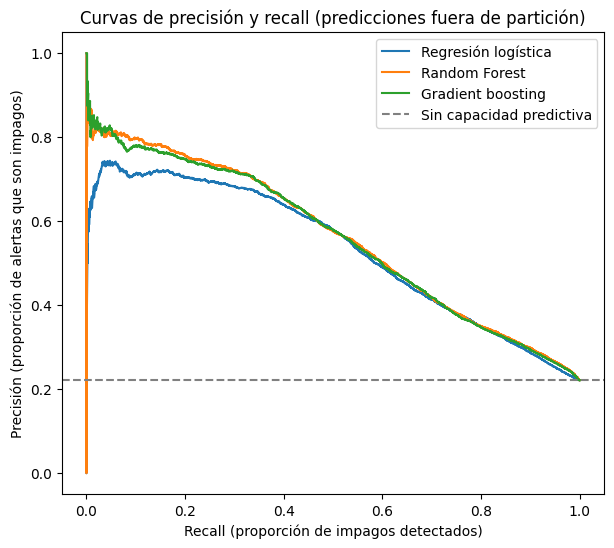

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, probabilities in out_of_fold_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_train, probabilities)
    ax.plot(recall, precision, label=model_name)
ax.axhline(y_train.mean(), color="grey", linestyle="--", label="Sin capacidad predictiva")
ax.set_title("Curvas de precisión y recall (predicciones fuera de partición)")
ax.set_xlabel("Recall (proporción de impagos detectados)")
ax.set_ylabel("Precisión (proporción de alertas que son impagos)")
ax.legend()
plt.show()

Las curvas de los dos modelos de árboles están por encima de la logística sobre todo a la izquierda, con recall bajo. Esa zona corresponde a los clientes de mayor riesgo: los árboles los identifican con más precisión. A partir de un recall de 0,5 las tres curvas prácticamente se superponen. Random Forest y gradient boosting son casi indistinguibles en todo el recorrido.

### 7.2 Decisión

- **Los dos modelos de árboles superan a la logística, pero por poco:** unos 0,025 de PR-AUC, con la ventaja concentrada en el 5–10 % de clientes de más riesgo.
- **Random Forest y gradient boosting empatan.** Elegimos el **Random Forest** porque da exactamente los mismos resultados en cualquier ordenador y es algo mejor con los clientes de más riesgo.
- **La regresión logística queda como alternativa:** pierde poco rendimiento y es mucho más fácil de explicar a clientes y reguladores.
